# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Chen 2021's prostate malignant manifold is **non-branching**: a single continuous sheet,
not a hub radiating to discrete subtypes. The correct topology is a **principal curve**
(ElPiGraph, non-branching by construction) fit on the joint Harmony/UMAP embedding — not a
re-embedding. We score the three embryonic modules here (needed to place the root), fit the
curve, root it at the Gast/pSom-high · Crest-low tip, and orient the panel to house style.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold
No re-embedding — cells keep their joint Harmony/UMAP coordinates. The strip aspect ratio
(major/minor singular value) confirms a near-1-D geometry.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

manifold: 14266 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.27


### Score embryonic modules (data-driven root placement)
The three developmental signatures (Gastrulation / Somitogenesis / Neural-crest) are scored
against the shared **union** control gene pool with `score_genes`, then graph-smoothed
(3 propagation steps on the kNN graph) to read *geography* rather than single-cell dropout.

In [4]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('spatial (smoothed) module correlations:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','pSom_sm'),('Crest_sm','Gast_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
print('-> Gast/pSom do NOT co-vary (no hub); the dominant axis is pSom vs Crest (inverse gradient).')

Gast: 75/81 genes present
pSom: 88/98 genes present
Crest: 103/104 genes present
spatial (smoothed) module correlations:
  Gast_sm vs pSom_sm: r = -0.11
  Crest_sm vs pSom_sm: r = -0.76
  Crest_sm vs Gast_sm: r = -0.15
-> Gast/pSom do NOT co-vary (no hub); the dominant axis is pSom vs Crest (inverse gradient).


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` are tuned for a **fold-free** monotone backbone: a node
self-approach ratio > 1 (minimum distance between graph-non-adjacent nodes in units of
median edge length) certifies the curve does not fold back on itself. `epg_mu=100` is
strong bending regularisation. The fit yields 2 tips, 0 forks — a clean linear backbone.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, "topology check failed"

curve: 2 tips, 0 forks | fold self-approach ratio = 2.83 (>1 = fold-free)


### Derive the root (data-driven) and pseudotime
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental
origin. Pseudotime then flows from that tip; the smoothed modules grade monotonically along
it (Gast/pSom decline, Crest rises to a terminal readout).

In [6]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for t in tps:
    m = np.isin(hard, np.where(D[t]<=3)[0])
    info[t] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {t}: Gast={info[t][0]:+.4f} pSom={info[t][1]:+.4f} Crest={info[t][2]:+.4f}')
root = int(max(tps, key=lambda t: info[t][0]+info[t][1]-info[t][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('gradient along pseudotime (Spearman rho):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=+0.0035 pSom=+0.0221 Crest=-0.0548
tip 2: Gast=+0.0053 pSom=+0.0354 Crest=-0.0685
derived root = tip 2 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho):
  Gast_sm: rho=-0.195 p=1.4e-122
  pSom_sm: rho=-0.352 p=0.0e+00
  Crest_sm: rho=+0.437 p=0.0e+00


### Reorient to house style (pseudotime left → right)
Orient using only raw UMAP coordinates with discrete axis flips (no rotation/interpolation
— an SVD basis can be a reflection and silently flip an axis). Here the trajectory's major
axis is already **horizontal** in the raw embedding (raw-x correlates with pseudotime at
|r|≈0.94), so a single x-flip gives left→right — no x↔y swap is needed (this differs from
Kürten, whose strip was vertical).

In [7]:
xy = adata.obsm['X_umap'].copy(); t = adata.obs['t'].values
xyr = np.column_stack([-xy[:,0], xy[:,1]])        # x-flip only (no swap)
r = float(np.corrcoef(xyr[:,0], t)[0,1])
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
adata.obsm['X_umap_lin'] = xyr
print(f'orientation: x-flip (no swap); corr(x_lin, pseudotime) = {r:+.2f}')

orientation: x-flip (no swap); corr(x_lin, pseudotime) = +0.94


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


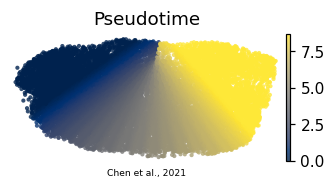

In [8]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = adata.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Chen et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')